# 07 — Validation error analysis (training folds only)
**Objective:** Diagnose the model selected in notebook 06 without peeking at the held-out test set. We use **out-of-fold predictions** so every row is predicted by a model that did not train on that row. Then we investigate where predictions fail.

In [1]:
from pathlib import Path
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import GroupKFold, cross_val_predict
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.base import clone
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
df = pd.read_csv(ROOT / "data/processed/cleaned_cars.csv" if (ROOT / "data/processed/cleaned_cars.csv").exists() else ROOT / "data/raw/car_details.csv")
features = ["year", "km_driven", "fuel", "seller_type", "transmission", "owner"]
X, y = df[features], df["selling_price"]
split = joblib.load(ROOT / "models/split_indices.joblib")
idx = split["train_idx"]
X_train, y_train = X.iloc[idx], y.iloc[idx]
groups_train = pd.util.hash_pandas_object(X_train, index=False)
model = joblib.load(ROOT / "models/baseline_candidate.joblib")

In [2]:
oof_predictions = cross_val_predict(
    clone(model), X_train, y_train,
    groups=groups_train, cv=GroupKFold(n_splits=5), n_jobs=1
)
validation = X_train.copy()
validation["actual_price"] = y_train
validation["predicted_price"] = oof_predictions
validation["error"] = validation["predicted_price"] - validation["actual_price"]
validation["absolute_error"] = validation["error"].abs()
validation["price_segment"] = pd.cut(validation["actual_price"], bins=[0, 200000, 500000, 1000000, np.inf], labels=["<=2L", "2L-5L", "5L-10L", ">10L"])
print("OOF MAE (INR):", round(mean_absolute_error(y_train, oof_predictions)))
print("OOF RMSE (INR):", round(np.sqrt(mean_squared_error(y_train, oof_predictions))))
print("OOF R²:", round(r2_score(y_train, oof_predictions), 3))

OOF MAE (INR): 203642
OOF RMSE (INR): 421938
OOF R²: 0.475


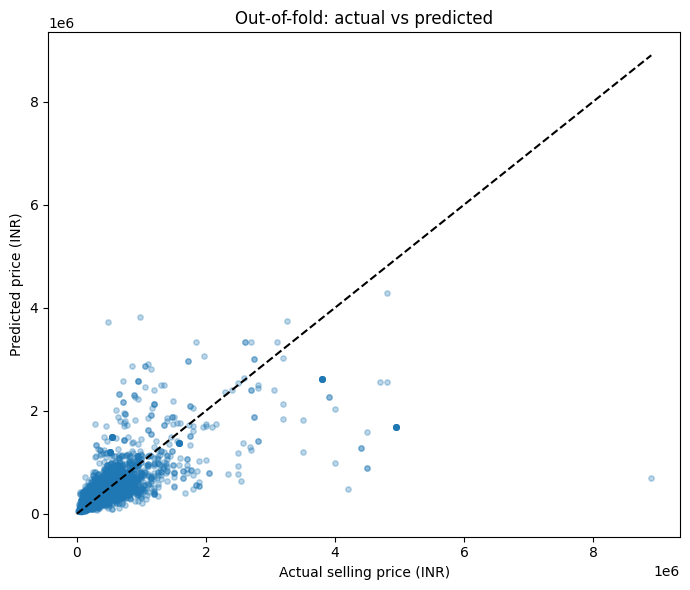

In [3]:
fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(validation["actual_price"], validation["predicted_price"], alpha=0.3, s=15)
maximum = max(validation["actual_price"].max(), validation["predicted_price"].max())
ax.plot([0, maximum], [0, maximum], linestyle="--", color="black")
ax.set(xlabel="Actual selling price (INR)", ylabel="Predicted price (INR)", title="Out-of-fold: actual vs predicted")
fig.tight_layout()
fig.savefig(ROOT / "reports/figures/validation_actual_vs_predicted.png", dpi=150)
plt.show()

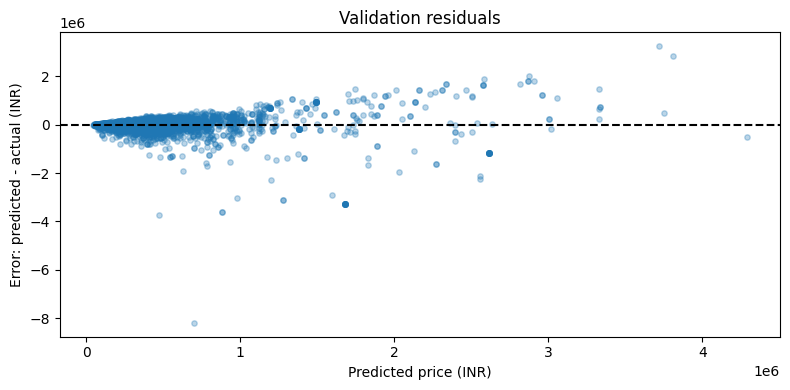

In [4]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.scatter(validation["predicted_price"], validation["error"], alpha=0.3, s=15)
ax.axhline(0, linestyle="--", color="black")
ax.set(xlabel="Predicted price (INR)", ylabel="Error: predicted - actual (INR)", title="Validation residuals")
fig.tight_layout()
fig.savefig(ROOT / "reports/figures/validation_residuals.png", dpi=150)
plt.show()

In [5]:
segment_report = validation.groupby("price_segment", observed=True).agg(
    listings=("absolute_error", "size"),
    median_actual_price=("actual_price", "median"),
    mean_absolute_error=("absolute_error", "mean"),
    mean_signed_error=("error", "mean")
).round(0)
print(segment_report.to_string())
segment_report.to_csv(ROOT / "reports/validation_error_by_price_segment.csv")
print("\n10 largest validation errors:")
print(validation.nlargest(10, "absolute_error")[features + ["actual_price", "predicted_price", "absolute_error"]].to_string(index=False))

               listings  median_actual_price  mean_absolute_error  mean_signed_error
price_segment                                                                       
<=2L                878             125000.0              87650.0            78193.0
2L-5L              1437             320000.0             131581.0            69569.0
5L-10L              866             650000.0             241371.0            -1886.0
>10L                267            1500000.0             850535.0          -596301.0

10 largest validation errors:
 year  km_driven   fuel seller_type transmission       owner  actual_price  predicted_price  absolute_error
 2016      13000 Petrol      Dealer    Automatic First Owner       8900000     7.012187e+05    8.198781e+06
 2010     100000 Diesel      Dealer    Automatic First Owner       4200000     4.745619e+05    3.725438e+06
 2018       9800 Petrol      Dealer    Automatic First Owner       4500000     8.829528e+05    3.617047e+06
 2018       9800 Petrol    

### Business interpretation
- **Positive signed error:** the model overestimates prices; **negative:** it underestimates.
- Check whether errors are larger for expensive cars, automatic transmissions, or rare fuel categories.
- Explain possible limitations: no vehicle condition, city, model variant, or verified listing date.
- These are **validation** diagnostics, not final test results. Move to notebook 08 for tuning and a one-time holdout evaluation.